# RandomSelector: speed and reproducibility

This notebook times RandomSelector against its original and checks that every
fit gives the same features.

**Variants.** The first is the original. RandomSelector has no original to compare with: only its own series. The others are
this package's versions:

- **featsel**: its defaults.

**Data.** Synthetic, shaped like SCAN-B: 3,000 patients, one in five
positive, 50 informative genes among 30,000. Each variant fits on the first
1,000, 3,000, 10,000 and 30,000 genes.

**Each row of the table.** One variant at one gene count:

- `median_s`, `min_s`, `max_s`: seconds per fit, over 2 timed fits after one untimed fit (CUDA starts then). A variant whose first fit passes 60 s is fit once more only, and its larger sizes are skipped.
- `reproducible`: every fit, the untimed one included, chose the same features. Each fit is by a fresh selector.
- `jaccard_vs_original`: overlap of its features with the original's at the same size; 1 is the same features.

**Why 2 timed fits.** They are enough to see a gap of several times, such
as an original against a GPU version. To measure a gap of a few percent,
between two small changes, pass a larger `repeats` to `benchmark()` and fit
the two versions alternately: drift in the machine's speed (power, heat)
shifts all later fits, and more repeats do not remove it.

Times hold for this machine only. The JSON written beside the CSV records it.


In [1]:
import json
from pathlib import Path

import featsel
from featsel import benchmark, environment

NAME = 'RandomSelector'
OUT = Path(featsel.__file__).parents[1] / 'results' / 'local' / 'speed' / f'{NAME}.csv'

print(f"Memory cap: {benchmark.cap_memory():.1f} GB")
X, y = benchmark.synthetic()
print(f"{X.shape[0]} patients x {X.shape[1]} genes, {y.sum()} positive")
print("Variants:", ', '.join(benchmark.variants(NAME)))

Memory cap: 9.2 GB


3000 patients x 30000 genes, 603 positive


Variants: featsel


In [2]:
table = benchmark.benchmark(NAME, X, y)
OUT.parent.mkdir(parents=True, exist_ok=True)
table.to_csv(OUT, index=False)
environment.write_json(OUT.with_suffix('.json'), selector=NAME,
                       params=benchmark.PARAMS[NAME], n_patients=int(X.shape[0]))
table.round(4)

,variant,device,n_genes,n_patients,fits,median_s,min_s,max_s,n_selected,reproducible,jaccard_vs_original
0,featsel,cpu,1000,3000,3,0.0011,0.0010,0.0013,50,True,1.0
1,featsel,cpu,3000,3000,3,0.0028,0.0026,0.0030,50,True,1.0
2,featsel,cpu,10000,3000,3,0.0085,0.0078,0.0091,50,True,1.0
3,featsel,cpu,30000,3000,3,0.0242,0.0239,0.0244,50,True,1.0


In [3]:
# Reproducibility: every fit of every variant chose the same features.
print("Every fit reproduced its features:", bool(table['reproducible'].all()))

# Against the original: the same features, and the speed at the largest
# size both reached.
if table['variant'].nunique() > 1:
    print("Same features as the original at every size:",
          bool((table['jaccard_vs_original'] == 1).all()))
    first = table['variant'].iloc[0]
    original = table[table['variant'] == first].set_index('n_genes')['median_s']
    for variant, part in table.groupby('variant', sort=False):
        times = part.set_index('n_genes')['median_s']
        n = times.index.intersection(original.index).max()
        print(f"{variant:24s} {times[n]:9.3f} s at {n:6d} genes, "
              f"{original[n] / times[n]:.1f}x the original's speed")

Every fit reproduced its features: True


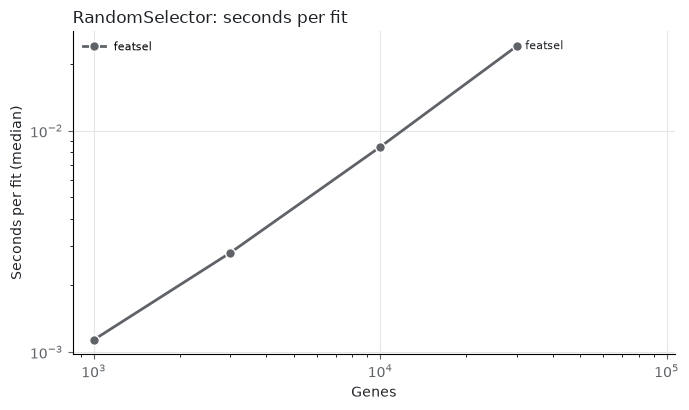

In [4]:
fig = benchmark.plot(table, f"{NAME}: seconds per fit")